DATASET LOADED SUCCESSFULLY
Shape: (649, 33)


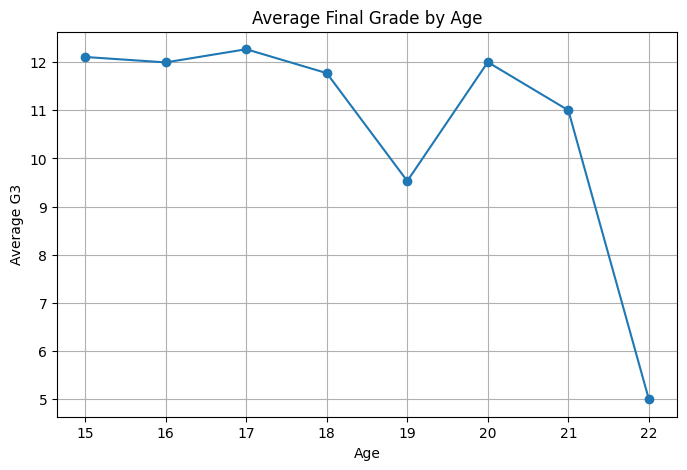

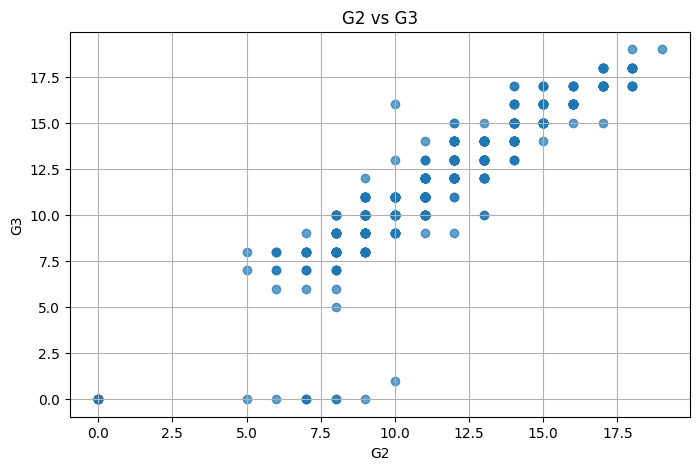

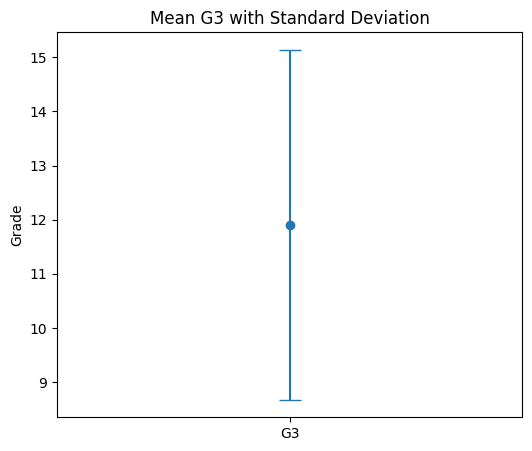

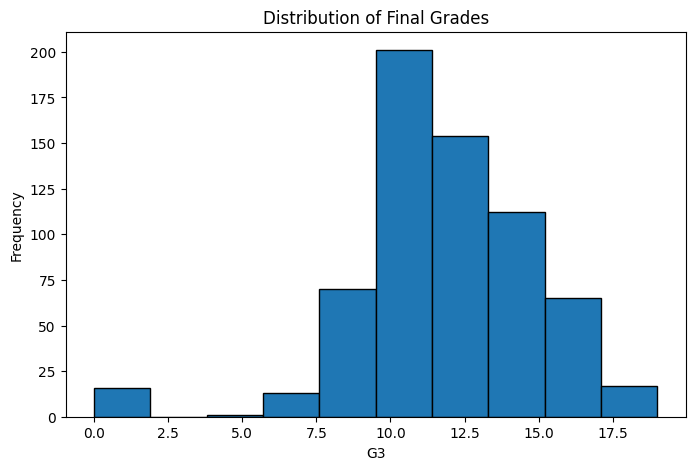

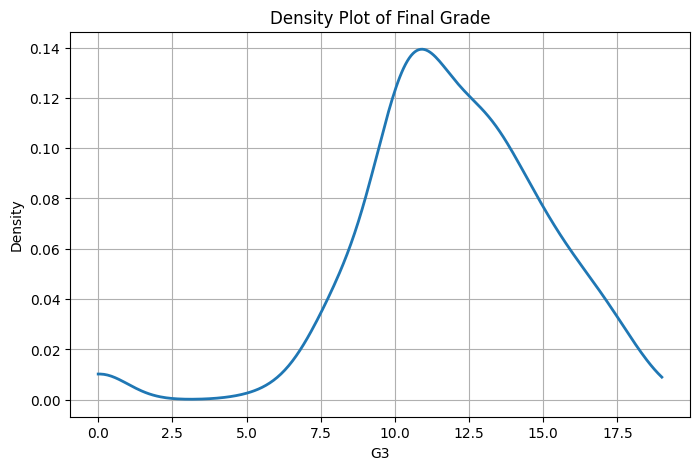

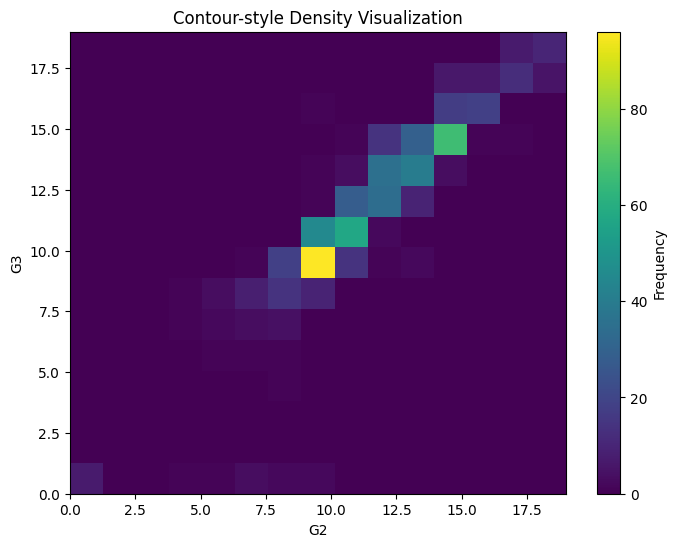

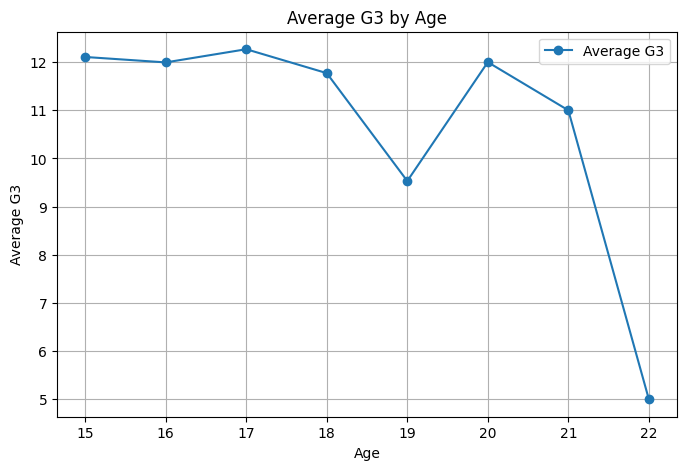

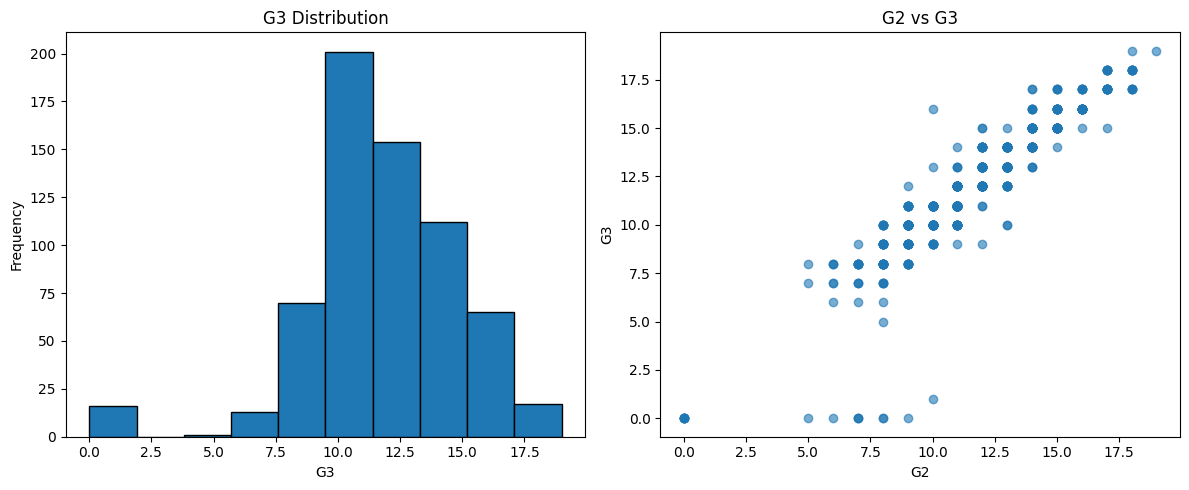

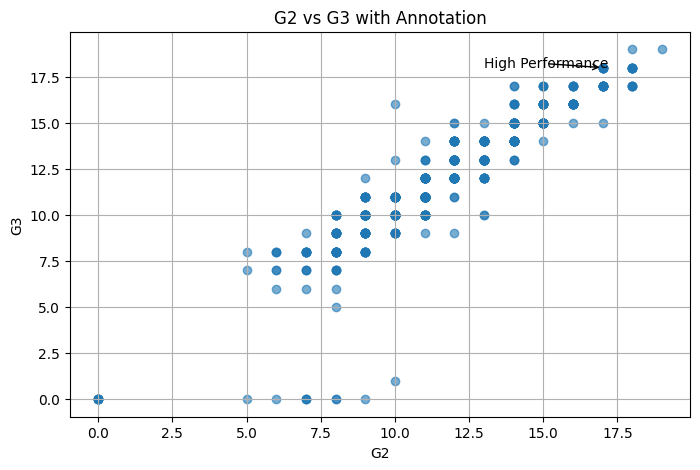

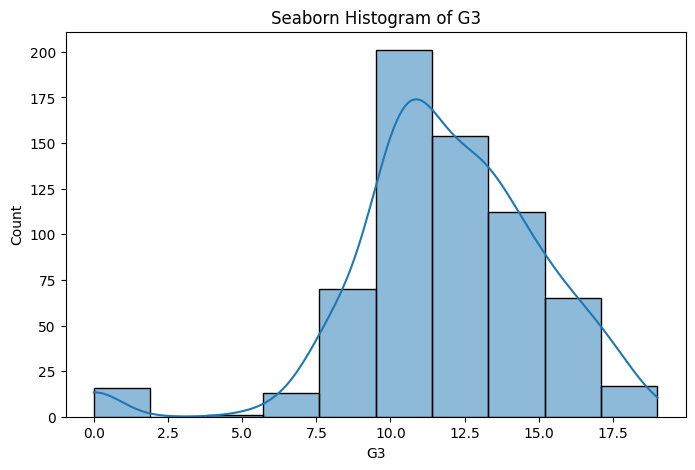

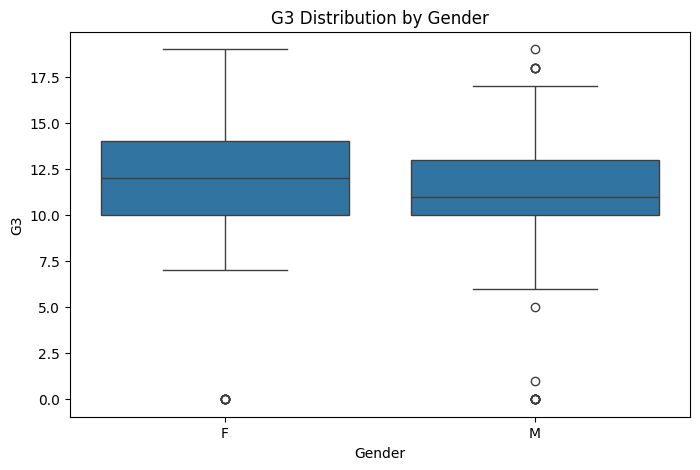

VISUALIZATION COMPLETED SUCCESSFULLY


In [ ]:
!pip -q install ucimlrepo plotly bokeh

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from ucimlrepo import fetch_ucirepo
from bokeh.plotting import figure, show
from bokeh.io import output_notebook

output_notebook()

student_performance = fetch_ucirepo(id=320)

X = student_performance.data.features
y = student_performance.data.targets

df = pd.concat([X, y], axis=1)

print("DATASET LOADED SUCCESSFULLY")
print("Shape:", df.shape)

# Line Plot
plt.figure(figsize=(8, 5))

mean_g3_age = df.groupby("age")["G3"].mean()

plt.plot(
    mean_g3_age.index,
    mean_g3_age.values,
    marker="o"
)

plt.xlabel("Age")
plt.ylabel("Average G3")
plt.title("Average Final Grade by Age")
plt.grid(True)
plt.show()


# Scatter Plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df["G2"],
    df["G3"],
    alpha=0.7
)

plt.xlabel("G2")
plt.ylabel("G3")
plt.title("G2 vs G3")
plt.grid(True)
plt.show()


# Error Visualization
mean_g3 = df["G3"].mean()
std_g3 = df["G3"].std()

plt.figure(figsize=(6, 5))

plt.errorbar(
    ["G3"],
    [mean_g3],
    yerr=[std_g3],
    fmt="o",
    capsize=8
)

plt.ylabel("Grade")
plt.title("Mean G3 with Standard Deviation")
plt.show()


# Histogram
plt.figure(figsize=(8, 5))

plt.hist(
    df["G3"],
    bins=10,
    edgecolor="black"
)

plt.xlabel("G3")
plt.ylabel("Frequency")
plt.title("Distribution of Final Grades")
plt.show()


# Density Plot
values = df["G3"].dropna().values

x = np.linspace(
    values.min(),
    values.max(),
    300
)

bandwidth = 1.06 * values.std() * len(values) ** (-1 / 5)

density = np.zeros_like(x)

for value in values:
    density += np.exp(
        -0.5 * ((x - value) / bandwidth) ** 2
    )

density = density / (
    len(values) * bandwidth * np.sqrt(2 * np.pi)
)

plt.figure(figsize=(8, 5))

plt.plot(
    x,
    density,
    linewidth=2
)

plt.xlabel("G3")
plt.ylabel("Density")
plt.title("Density Plot of Final Grade")
plt.grid(True)
plt.show()


# Contour Plot
x_values = df["G2"]
y_values = df["G3"]

plt.figure(figsize=(8, 6))

plt.hist2d(
    x_values,
    y_values,
    bins=15
)

plt.colorbar(label="Frequency")

plt.xlabel("G2")
plt.ylabel("G3")
plt.title("Contour-style Density Visualization")
plt.show()


# Legend and Colors
plt.figure(figsize=(8, 5))

plt.plot(
    mean_g3_age.index,
    mean_g3_age.values,
    marker="o",
    label="Average G3"
)

plt.xlabel("Age")
plt.ylabel("Average G3")
plt.title("Average G3 by Age")
plt.legend()
plt.grid(True)
plt.show()


# Subplots
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

axes[0].hist(
    df["G3"],
    bins=10,
    edgecolor="black"
)

axes[0].set_title("G3 Distribution")
axes[0].set_xlabel("G3")
axes[0].set_ylabel("Frequency")

axes[1].scatter(
    df["G2"],
    df["G3"],
    alpha=0.6
)

axes[1].set_title("G2 vs G3")
axes[1].set_xlabel("G2")
axes[1].set_ylabel("G3")

plt.tight_layout()
plt.show()


# Text and Annotation
plt.figure(figsize=(8, 5))

plt.scatter(
    df["G2"],
    df["G3"],
    alpha=0.6
)

plt.xlabel("G2")
plt.ylabel("G3")
plt.title("G2 vs G3 with Annotation")

plt.annotate(
    "High Performance",
    xy=(17, 18),
    xytext=(13, 18),
    arrowprops=dict(arrowstyle="->")
)

plt.grid(True)
plt.show()


# 3D Visualization
fig = px.scatter_3d(
    df,
    x="studytime",
    y="G2",
    z="G3",
    color="sex",
    title="3D Visualization of Student Performance"
)

fig.show()


# Seaborn Histogram
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="G3",
    bins=10,
    kde=True
)

plt.title("Seaborn Histogram of G3")
plt.xlabel("G3")
plt.ylabel("Count")
plt.show()


# Seaborn Boxplot
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="G3"
)

plt.title("G3 Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("G3")
plt.show()


# Plotly Scatter Plot
fig = px.scatter(
    df,
    x="G2",
    y="G3",
    color="sex",
    hover_data=[
        "age",
        "studytime",
        "absences"
    ],
    title="Interactive G2 vs G3"
)

fig.show()


# Plotly 3D
fig = px.scatter_3d(
    df,
    x="age",
    y="studytime",
    z="G3",
    color="sex",
    title="Interactive 3D Student Performance"
)

fig.show()


# Bokeh Visualization
bokeh_plot = figure(
    title="Bokeh - G2 vs G3",
    x_axis_label="G2",
    y_axis_label="G3",
    width=700,
    height=500
)

bokeh_plot.scatter(
    df["G2"],
    df["G3"],
    size=7,
    alpha=0.5
)

show(bokeh_plot)

print("VISUALIZATION COMPLETED SUCCESSFULLY")